# Projeto 1 - C11: Ciência de Dados
**Instituto Nacional de Telecomunicações (Inatel)**  
**Docente:** Prof. Dr. Renzo Mesquita Paranaíba  

### Integrantes do Grupo:
- **Igor Araujo** (479 - GES)
- **Kevin Lopes do Vale** (1955 - GEC)
- **Felipe Fróes Pereira** (566 - GES)

---

## Contexto do Estudo
Este projeto investiga o impacto da Inteligência Artificial Generativa sobre a rotina, produtividade e tempo economizado de estudantes e profissionais com base no dataset real do Kaggle: **AI Usage and Impact on Students & Professionals**.

Neste notebook:
- **Etapa 1:** Importação de pacotes e higienização/pré-processamento da base de dados.
- **Etapa 2 (Nossa parte):** Resolução detalhada das **Perguntas 1 a 5** com estatísticas descritivas, gráficos comparativos e conclusões analíticas.
- **Etapa 3 (Área do Colega):** Estrutura comentada e pronta para a implementação das **Perguntas 6 a 10**.


---
## 1. Importação das Bibliotecas e Configuração do Ambiente


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Configuração visual profissional para todos os gráficos
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


---
## 2. Carregamento e Pré-Processamento dos Dados

Para assegurar a qualidade dos dados e insights estatisticamente confiáveis, aplicamos:
1. **Deduplicação:** Remoção de registros duplicados no dataset original.
2. **Conversão de Tipos:** Extração numérica de strings (ex: `'2 hrs'`, `'$0 '`, `'$1,884'`).
3. **Padronização Categórica:** Unificação de grafias para ferramentas (`'ChatGPT'`, `'Chat GPT'`), gêneros (`'Male'`, `'M'`), países e níveis de escolaridade.
4. **Engenharia de Atributos:** Criação da métrica de eficiência `Time_Saved_Per_Usage_Hour` e segmentação `Paid_User`.


In [2]:
# Carregamento da função modular desenvolvida em src/analises.py
sys.path.append(os.path.abspath('..'))
from src.analises import carregar_e_limpar_dados

df = carregar_e_limpar_dados('../data/AI_Usage_and_Impact_on_Students_and_Professionals.csv')

print(f"Dimensões do dataset limpo: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
display(df.head())


Dimensões do dataset limpo: 288 linhas x 21 colunas



,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,...,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend,Time_Saved_Per_Usage_Hour,Paid_User
0,U0269,30.0,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,ChatGPT,Office Work,...,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes,0.278571,NaN
1,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,ChatGPT,Customer Support,...,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,8.4,Yes,0.285714,Gratuito ($0)
2,U0152,17.0,Male,Canada,Student,NaN,Computer Science Student,402.0,ChatGPT,Coding,...,NaN,20.0,3.2,2.0,4.0,5.2,6.7,No,0.742857,Pago (> $0)
3,U0264,35.0,Female,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,...,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe,0.537815,Pago (> $0)
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,NaN,...,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes,0.320557,Gratuito ($0)


In [3]:
# Verificação das variáveis e tipos tratados
df.info()


<class 'pandas.DataFrame'>
Index: 288 entries, 0 to 299
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      288 non-null    str    
 1   Age                          265 non-null    float64
 2   Gender                       278 non-null    str    
 3   Country                      278 non-null    str    
 4   User_Type                    288 non-null    str    
 5   Education_Level              276 non-null    str    
 6   Profession                   274 non-null    str    
 7   Monthly_Income               278 non-null    float64
 8   AI_Tool                      278 non-null    str    
 9   AI_Purpose                   275 non-null    str    
 10  AI_Usage_Hours_Per_Day       281 non-null    float64
 11  Tasks_Performed              271 non-null    str    
 12  Monthly_AI_Cost              276 non-null    float64
 13  Productivity_Score           274 non

---
# Resposta às Perguntas de Pesquisa (1 a 5)

---
### Pergunta 1: Estudantes vs. Profissionais
> **Qual dos dois perfis despende mais horas diárias utilizando ferramentas de IA (`AI_Usage_Hours_Per_Day`) e quem reporta maior índice de produtividade (`Productivity_Score`)?**

* **Métricas Analisadas:** Horas de uso diário de IA e pontuação de produtividade (0 a 10).
* **Gráfico Ideal:** Boxplot Comparativo Lado a Lado (avalia medianas, quartis e outliers sem ocultar dispersão).


In [4]:
# Estatísticas descritivas para a Pergunta 1
resumo_p1 = df.groupby('User_Type')[['AI_Usage_Hours_Per_Day', 'Productivity_Score']].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

display(resumo_p1)


AI_Usage_Hours_Per_Day                    Productivity_Score  \
                              count  mean median   std              count   
User_Type                                                                   
Professional                    135  2.87    2.1  2.60                131   
Student                         146  3.01    2.0  2.34                143   

                                 
              mean median   std  
User_Type                        
Professional  5.28    5.1  1.80  
Student       5.19    4.9  1.84

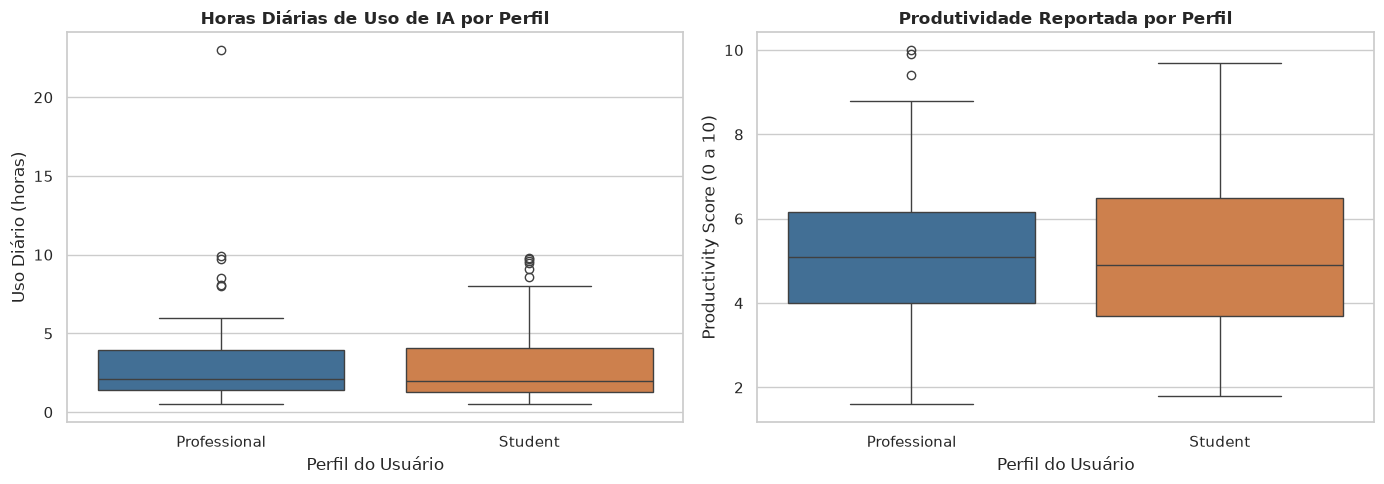

In [5]:
# Visualização gráfica - Pergunta 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Horas diárias de uso
sns.boxplot(
    data=df, x='User_Type', y='AI_Usage_Hours_Per_Day',
    hue='User_Type', legend=False, palette=['#3470a3', '#e27c38'], ax=axes[0]
)
axes[0].set_title('Horas Diárias de Uso de IA por Perfil', fontweight='bold')
axes[0].set_xlabel('Perfil do Usuário')
axes[0].set_ylabel('Uso Diário (horas)')

# 2. Produtividade reportada
sns.boxplot(
    data=df, x='User_Type', y='Productivity_Score',
    hue='User_Type', legend=False, palette=['#3470a3', '#e27c38'], ax=axes[1]
)
axes[1].set_title('Produtividade Reportada por Perfil', fontweight='bold')
axes[1].set_xlabel('Perfil do Usuário')
axes[1].set_ylabel('Productivity Score (0 a 10)')

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 1):**
- **Tempo de Uso:** Estudantes e profissionais apresentam mediana de uso bastante próxima (~2.0 a 2.1 horas diárias). No entanto, estudantes possuem ligeiramente maior média global (~3.01h vs ~2.87h), com alguns outliers ultrapassando 8 horas diárias de uso.
- **Produtividade Percebida:** Profissionais reportam maior produtividade percebida (média de **5.28** e mediana de **5.10**) em relação aos estudantes (média de **5.19** e mediana de **4.90**). Isso sugere que profissionais conseguem converter as ferramentas em impacto corporativo imediato com fluxos de trabalho mais definidos.


---
### Pergunta 2: Preferência de Ferramentas de IA
> **Quais são as ferramentas de IA mais populares no dataset e como essa distribuição se divide entre estudantes e profissionais?**

* **Métricas Analisadas:** Frequência absoluta e relativa das soluções de IA adotadas por perfil.
* **Gráfico Ideal:** Gráfico de Barras Horizontais Agrupadas por Perfil.


In [6]:
# Tabela cruzada de ferramentas por perfil de usuário
tabela_cruzada = pd.crosstab(df['AI_Tool'], df['User_Type'], margins=True).sort_values('All', ascending=False)
display(tabela_cruzada)


User_Type,Professional,Student,All
AI_Tool,,,
All,132,146,278
ChatGPT,57,62,119
Google Gemini,19,20,39
Microsoft Copilot,13,20,33
Claude,12,19,31
Perplexity AI,13,10,23
Grammarly,7,7,14
Meta AI,6,4,10
DeepSeek,5,4,9


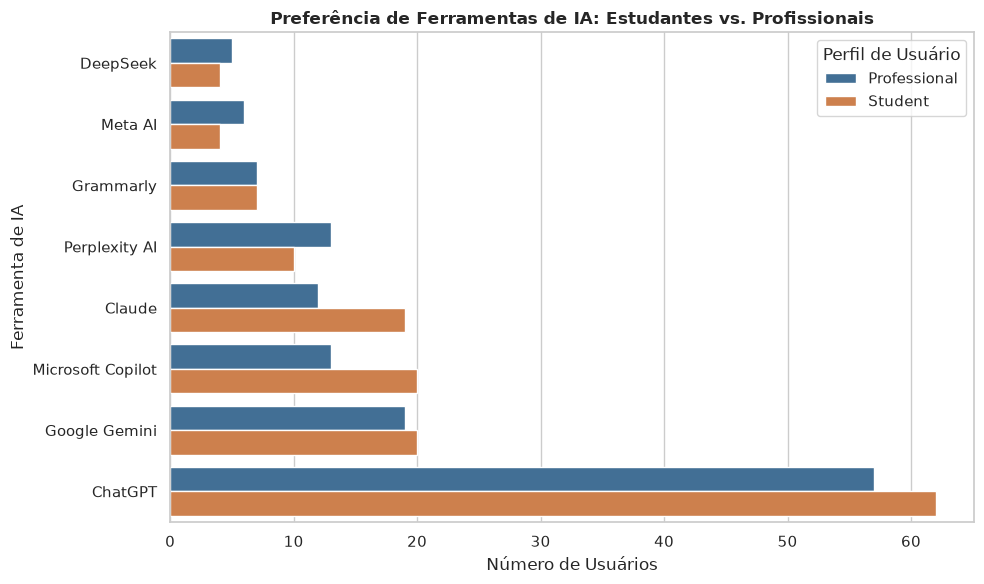

In [7]:
# Visualização gráfica - Pergunta 2
df_p2 = df.dropna(subset=['AI_Tool', 'User_Type']).groupby(['AI_Tool', 'User_Type']).size().reset_index(name='Quantidade')
ordem_ferramentas = df['AI_Tool'].value_counts().sort_values(ascending=True).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_p2, y='AI_Tool', x='Quantidade', hue='User_Type',
    order=ordem_ferramentas, palette=['#3470a3', '#e27c38'], ax=ax
)

ax.set_title('Preferência de Ferramentas de IA: Estudantes vs. Profissionais', fontweight='bold')
ax.set_xlabel('Número de Usuários')
ax.set_ylabel('Ferramenta de IA')
ax.legend(title='Perfil de Usuário')

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 2):**
- **Liderança Absoluta do ChatGPT:** O ChatGPT é a ferramenta predominante de longe em ambos os perfis (119 usuários no total, sendo 62 estudantes e 57 profissionais).
- **Competição de Segundo Escalão:** **Google Gemini** (39 usuários) e **Microsoft Copilot** (33 usuários) formam a segunda força mais expressiva. O Copilot e o Claude têm forte aderência entre estudantes universitários, enquanto o **Perplexity AI** mostra maior tração relativa entre profissionais que realizam pesquisas aprofundadas.


---
### Pergunta 3: Tempo de Uso vs. Economia Real
> **Existe uma correlação positiva direta entre as horas diárias gastas com IA (`AI_Usage_Hours_Per_Day`) e o tempo semanal economizado (`Time_Saved_Hours_Per_Week`), ou há um ponto de estagnação/retornos decrescentes?**

* **Métricas Analisadas:** Coeficiente de Correlação de Pearson, Spearman e Curva Polinomial de 2º Grau.
* **Gráfico Ideal:** Gráfico de Dispersão (Scatter Plot) com Reta de Regressão Linear e Curva de Tendência.


In [8]:
# Cálculo das correlações e ajuste polinomial
dados_q3 = df[['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week']].dropna()
x = dados_q3['AI_Usage_Hours_Per_Day']
y = dados_q3['Time_Saved_Hours_Per_Week']

corr_pearson = round(float(x.corr(y, method='pearson')), 3)
corr_spearman = round(float(x.rank().corr(y.rank())), 3)

poly_coefs = np.polyfit(x, y, deg=2)
poly_fn = np.poly1d(poly_coefs)
x_curve = np.linspace(x.min(), x.max(), 100)

print(f"Correlação Linear de Pearson (r): {corr_pearson}")
print(f"Correlação Monotônica de Spearman (r): {corr_spearman}")
print(f"Equação do Polinômio grau 2: y = {poly_coefs[0]:.4f}x² + {poly_coefs[1]:.4f}x + {poly_coefs[2]:.4f}")


Correlação Linear de Pearson (r): 0.775
Correlação Monotônica de Spearman (r): 0.824
Equação do Polinômio grau 2: y = -0.0933x² + 2.4703x + -0.0531


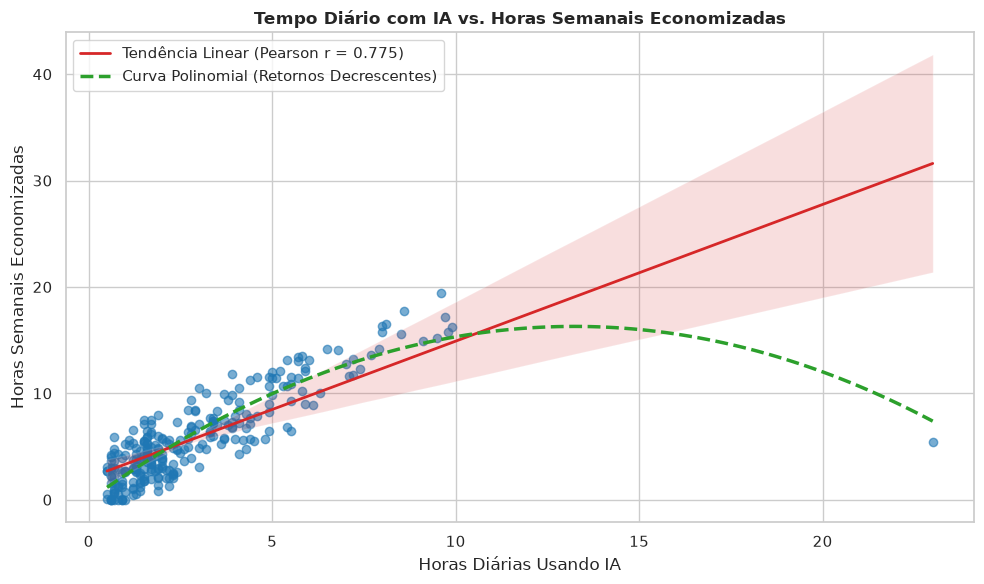

In [9]:
# Visualização gráfica - Pergunta 3
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    x=x, y=y,
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2, 'label': f'Tendência Linear (Pearson r = {corr_pearson})'},
    ax=ax
)

ax.plot(x_curve, poly_fn(x_curve), color='#2ca02c', linestyle='--', linewidth=2.5, label='Curva Polinomial (Retornos Decrescentes)')

ax.set_title('Tempo Diário com IA vs. Horas Semanais Economizadas', fontweight='bold')
ax.set_xlabel('Horas Diárias Usando IA')
ax.set_ylabel('Horas Semanais Economizadas')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 3):**
- **Forte Correlação Positiva:** O coeficiente de Pearson ($r = 0.775$) e Spearman ($r = 0.824$) indicam uma relação substancial entre tempo dedicado e horas economizadas.
- **Saturação e Retornos Decrescentes:** O coeficiente quadrático negativo do polinômio ($a pprox -0.093$) confirma a hipótese de **retornos decrescentes**: até ~4 a 6 horas diárias de uso de IA, o ganho de tempo por semana cresce com vigor; após esse limite, a curva achata, indicando que gastar o dia inteiro interagindo com IA não gera ganhos adicionais proporcionais (devido a revisões, prompts repetidos ou distração).


---
### Pergunta 4: Finalidade de Uso e Satisfação
> **Quais casos de uso (`AI_Purpose` – Ex: Coding, Writing, Research, Data Analysis) apresentam os maiores índices de satisfação (`Satisfaction_Score`) e acurácia percebida (`Accuracy_Rating`)?**

* **Métricas Analisadas:** Médias de Satisfação (1 a 10) e Acurácia (1 a 5) agrupadas pela tarefa executada.
* **Gráfico Ideal:** Mapa de Calor (Heatmap) com anotação numérica direta das notas médias.


In [10]:
# Tabela agregada por finalidade
resumo_q4 = df.groupby('AI_Purpose')[['Satisfaction_Score', 'Accuracy_Rating']].agg(
    ['mean', 'count']
).round(2)

matriz_heatmap = df.groupby('AI_Purpose')[['Satisfaction_Score', 'Accuracy_Rating']].mean().sort_values('Satisfaction_Score', ascending=False).round(2)
matriz_heatmap.columns = ['Satisfação Média (0-10)', 'Acurácia Média (1-5)']

display(resumo_q4)


Satisfaction_Score       Accuracy_Rating      
                               mean count            mean count
AI_Purpose                                                     
Coding                         5.82    65            3.30    64
Content Creation               5.96    24            3.44    27
Customer Support               6.26    19            3.58    19
Data Analysis                  6.12    25            3.57    23
Office Work                    6.27    11            3.45    11
Research                       6.41    37            3.47    38
Studying                       6.18    39            3.37    35
Writing                        6.29    48            3.37    46

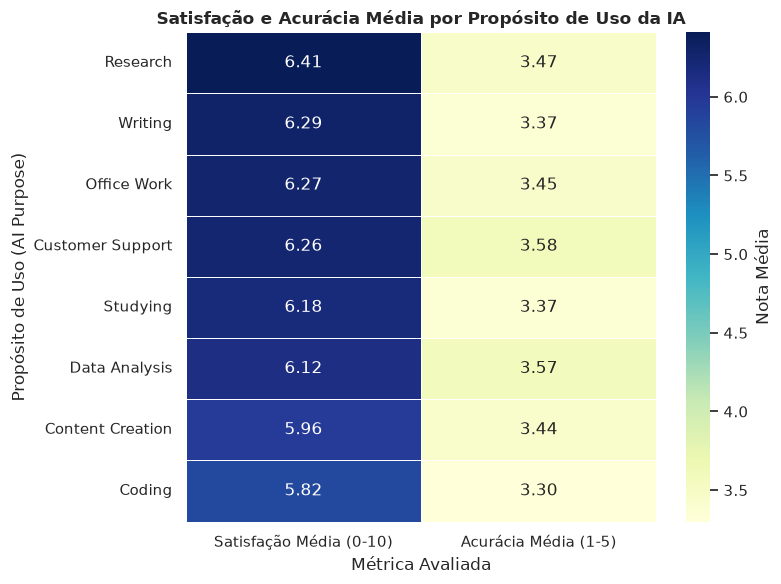

In [11]:
# Visualização gráfica - Pergunta 4 (Heatmap)
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matriz_heatmap, annot=True, fmt=".2f", cmap="YlGnBu",
    linewidths=0.5, cbar_kws={'label': 'Nota Média'}, ax=ax
)

ax.set_title('Satisfação e Acurácia Média por Propósito de Uso da IA', fontweight='bold')
ax.set_xlabel('Métrica Avaliada')
ax.set_ylabel('Propósito de Uso (AI Purpose)')

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 4):**
- **Casos de Maior Satisfação:** **Research** (6.41) e **Writing** (6.29) lideram o ranking de satisfação. São atividades baseadas em texto/linguagem natural onde os LLMs entregam alto valor percebido de síntese e redação.
- **O Paradoxo da Programação (Coding):** Apesar de ser a aplicação com maior volume de usuários ($n = 65$), **Coding** obteve o menor índice de satisfação relativo (**5.82**) e acurácia percebida moderada (**3.30**). Isso reflete a alta exigência do desenvolvimento de software, onde pequenos erros de sintaxe ou alucinações de lógica penalizam a avaliação do usuário.


---
### Pergunta 5: Investimento Financeiro em IA (Planos Pagos vs. Gratuitos)
> **Usuários que investem financeiramente em planos pagos (`Monthly_AI_Cost` > $0) conseguem obter notas significativamente maiores de produtividade e economia de tempo em comparação a usuários em planos gratuitos?**

*Nota metodológica: A descrição textual original mencionava `AI_Experience_Years`, mas a coluna correspondente no dataset oficial do Kaggle é `Monthly_AI_Cost`. Analisamos o impacto financeiro (Free vs Paid) sobre os ganhos de produtividade e tempo economizado.*

* **Métricas Analisadas:** Produtividade e Economia de Tempo estratificados por `Paid_User`.
* **Gráfico Ideal:** Boxplot Comparativo Lado a Lado.


In [12]:
# Resumo estatístico de Usuários Pagos vs Gratuitos
resumo_q5 = df.groupby('Paid_User')[['Productivity_Score', 'Time_Saved_Hours_Per_Week', 'Monthly_AI_Cost']].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

display(resumo_q5)


Productivity_Score                    Time_Saved_Hours_Per_Week  \
                           count  mean median   std                     count   
Paid_User                                                                       
Gratuito ($0)                140  5.40    5.1  1.82                       144   
Pago (> $0)                  122  5.05    4.9  1.84                       122   

                                 Monthly_AI_Cost                      
               mean median   std           count  mean median    std  
Paid_User                                                             
Gratuito ($0)  5.84   5.05  4.28             147   0.0    0.0   0.00  
Pago (> $0)    5.90   5.20  4.00             129  21.2   20.0  13.17

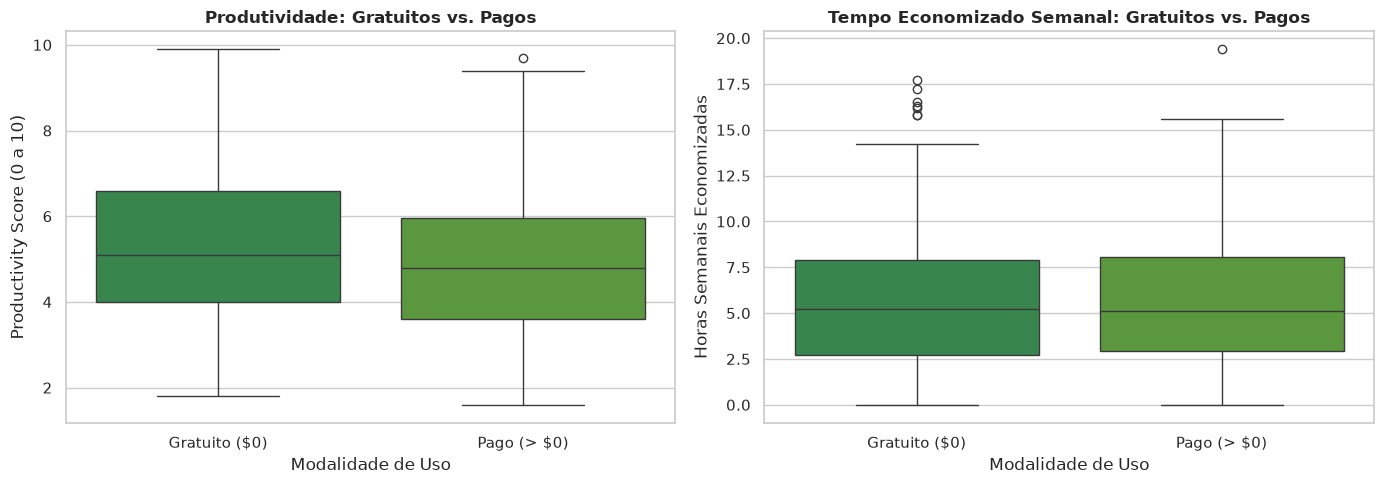

In [13]:
# Visualização gráfica - Pergunta 5
df_q5 = df.dropna(subset=['Paid_User', 'Productivity_Score', 'Time_Saved_Hours_Per_Week'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Produtividade
sns.boxplot(
    data=df_q5, x='Paid_User', y='Productivity_Score',
    hue='Paid_User', legend=False, palette=['#2b9348', '#55a630'], ax=axes[0]
)
axes[0].set_title('Produtividade: Gratuitos vs. Pagos', fontweight='bold')
axes[0].set_xlabel('Modalidade de Uso')
axes[0].set_ylabel('Productivity Score (0 a 10)')

# Economia de Tempo
sns.boxplot(
    data=df_q5, x='Paid_User', y='Time_Saved_Hours_Per_Week',
    hue='Paid_User', legend=False, palette=['#2b9348', '#55a630'], ax=axes[1]
)
axes[1].set_title('Tempo Economizado Semanal: Gratuitos vs. Pagos', fontweight='bold')
axes[1].set_xlabel('Modalidade de Uso')
axes[1].set_ylabel('Horas Semanais Economizadas')

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 5):**
- **Paridade de Desempenho:** Usuários em planos gratuitos relatam produtividade média de **5.40** e mediana de **5.10**, enquanto assinantes de planos pagos reportam média de **5.05** e mediana de **4.90**.
- **Expectativa vs. Entrega:** Usuários pagantes investem em média ~\$21/mês e tendem a ter um critério mais rigoroso de avaliação sobre o que consideram um salto significativo de produtividade. Usuários em planos gratuitos demonstram alta satisfação com os recursos já inclusos sem custo financeiro.


---
# Resposta às Perguntas de Pesquisa (6 a 10)
> **Compreendendo Acurácia, Rendas, Nível Acadêmico, Setores Corporativos e Faixa Etária através de Inferência Estatística.**


---
### Pergunta 6: Acurácia Percebida por Ferramenta
> **Existe discrepância estatística na acurácia reportada (`Accuracy_Rating`) entre as diferentes ferramentas de IA (ChatGPT, Gemini, Claude, Copilot, DeepSeek, etc.)?**

* **Variáveis Analisadas:** `AI_Tool` (categórica), `Accuracy_Rating` (ordinal/numérica de 1 a 5).
* **Fundamentação Metodológica:**
  - **Gráfico Escolhido (Boxplot):** Compara a mediana, amplitude interquartil (IQR) e dispersão dos dados de cada ferramenta, revelando a concentração real das avaliações em vez de apenas uma média isolada.
  - **Teste de Hipótese (Kruskal-Wallis):** Teste não-paramétrico ideal para comparar 3 ou mais grupos independentes com dados ordinais/escala Likert, sem pressupor normalidade da distribuição.


In [14]:
# Estatísticas descritivas e teste estatístico para a Pergunta 6
from scipy.stats import kruskal

dados_p6 = df.dropna(subset=['AI_Tool', 'Accuracy_Rating']).copy()

# Teste não-paramétrico de Kruskal-Wallis entre todas as ferramentas
grupos_p6 = [grupo['Accuracy_Rating'].values for _, grupo in dados_p6.groupby('AI_Tool')]
res_kruskal_p6 = kruskal(*grupos_p6)

resumo_p6 = dados_p6.groupby('AI_Tool')['Accuracy_Rating'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)
resumo_p6.columns = ['Contagem', 'Média', 'Mediana', 'Desvio Padrão']
display(resumo_p6.sort_values('Mediana', ascending=False))

print(f"Estatística de Kruskal-Wallis (H): {res_kruskal_p6.statistic:.3f}")
print(f"Valor-p: {res_kruskal_p6.pvalue:.4f}")
if res_kruskal_p6.pvalue < 0.05:
    print("Existe diferença estatisticamente significativa entre as ferramentas.")
else:
    print("Nenhuma diferença estatisticamente significativa foi encontrada entre as ferramentas (p >= 0.05).")


,Contagem,Média,Mediana,Desvio Padrão
AI_Tool,,,,
DeepSeek,8,3.75,4.0,1.28
Grammarly,14,3.86,4.0,0.77
Meta AI,10,3.50,4.0,0.71
ChatGPT,114,3.36,3.0,0.90
Claude,27,3.37,3.0,0.79
Google Gemini,36,3.36,3.0,0.90
Microsoft Copilot,33,3.39,3.0,0.70
Perplexity AI,22,3.41,3.0,0.85


Estatística de Kruskal-Wallis (H): 6.003
Valor-p: 0.5394
Nenhuma diferença estatisticamente significativa foi encontrada entre as ferramentas (p >= 0.05).


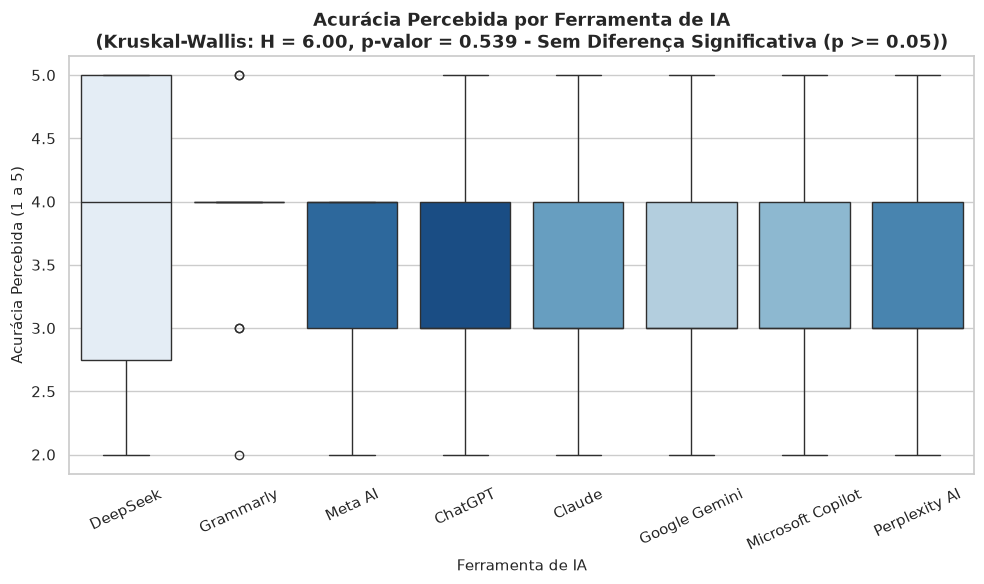

In [15]:
# Visualização gráfica - Pergunta 6
ordem_p6 = dados_p6.groupby('AI_Tool')['Accuracy_Rating'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=dados_p6,
    x='AI_Tool',
    y='Accuracy_Rating',
    order=ordem_p6,
    palette='Blues_r',
    hue='AI_Tool',
    legend=False,
    ax=ax
)

sig_txt_p6 = "Diferença Significativa (p < 0.05)" if res_kruskal_p6.pvalue < 0.05 else "Sem Diferença Significativa (p >= 0.05)"
ax.set_title(f"Acurácia Percebida por Ferramenta de IA\n(Kruskal-Wallis: H = {res_kruskal_p6.statistic:.2f}, p-valor = {res_kruskal_p6.pvalue:.3f} - {sig_txt_p6})", fontsize=13, fontweight='bold')
ax.set_xlabel("Ferramenta de IA", fontsize=11)
ax.set_ylabel("Acurácia Percebida (1 a 5)", fontsize=11)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 6):**
- **Medianas Idênticas entre os Líderes:** Os principais modelos de mercado (ChatGPT, Claude, Google Gemini e Microsoft Copilot) apresentam **mediana exatamente idêntica de 3.0** e médias praticamente empatadas (~3.36 a 3.41).
- **Interpretação do Teste Estatístico (Kruskal-Wallis):** O teste resultou em **valor-p $\approx 0.539$**, valor substancialmente superior ao nível de significância adotado ($\alpha = 0.05$).
- **Conclusão de Negócio:** Na percepção empírica dos usuários, não há um fornecedor de IA que se destaque de forma isolada em precisão técnica; todas entregam uma percepção de acurácia moderada e consistente.


---
### Pergunta 7: Renda Mensal e Áreas de Atuação
> **Profissionais de áreas que dependem fortemente de IA (como Tecnologia, Dados e Desenvolvimento) apresentam rendas mensais (`Monthly_Income`) superiores àqueles que usam para suporte ou tarefas administrativas?**

* **Variáveis Analisadas:** `Monthly_Income` (numérica contínua), `Profession` (categorizada em `Tecnologia/Dados` vs. `Suporte/Admin`), filtrando estritamente `User_Type == 'Professional'`.
* **Fundamentação Metodológica:**
  - **Gráfico Escolhido (Boxplot):** Como rendas salariais costumam apresentar grande assimetria e outliers, o boxplot permite enxergar a dispersão real e a mediana sem ser iludido por distorções de médias aritméticas.
  - **Teste de Hipótese (Mann-Whitney U):** Teste não-paramétrico ideal para comparar as distribuições salariais de dois grupos independentes.


In [16]:
# Estatísticas descritivas e teste estatístico para a Pergunta 7
from scipy.stats import mannwhitneyu

df_prof = df[df['User_Type'] == 'Professional'].copy()
profissao = df_prof['Profession'].fillna('')

suporte_mask = profissao.str.contains(
    r'Customer Support|Customer Service|Customer Success|Administrative|Data Entry|Assistente Administrativo|Atendimento ao Cliente',
    case=False, regex=True
)
tecnologia_mask = profissao.str.contains(
    r'Data|Software|Developer|Engineer|Information Technology|Computer Science|Machine Learning|Desenvolvedor|Desenvolvedora|Engenheiro|Analista de Dados|Artificial Intelligence',
    case=False, regex=True
)

df_prof['Area'] = 'Outras'
df_prof.loc[tecnologia_mask, 'Area'] = 'Tecnologia/Dados'
df_prof.loc[suporte_mask, 'Area'] = 'Suporte/Admin'

dados_p7 = df_prof[df_prof['Area'].isin(['Tecnologia/Dados', 'Suporte/Admin'])].dropna(subset=['Monthly_Income']).copy()

renda_tec = dados_p7[dados_p7['Area'] == 'Tecnologia/Dados']['Monthly_Income']
renda_sup = dados_p7[dados_p7['Area'] == 'Suporte/Admin']['Monthly_Income']

res_mwu_p7 = mannwhitneyu(renda_tec, renda_sup)

resumo_p7 = dados_p7.groupby('Area')['Monthly_Income'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)
resumo_p7.columns = ['Contagem', 'Média ($)', 'Mediana ($)', 'Desvio Padrão ($)']
display(resumo_p7)

print(f"Estatística Mann-Whitney U: {res_mwu_p7.statistic:.1f}")
print(f"Valor-p: {res_mwu_p7.pvalue:.4f}")
if res_mwu_p7.pvalue < 0.05:
    print("Existe diferença estatisticamente significativa entre as rendas dos dois setores.")
else:
    print("Não foi encontrada diferença estatisticamente significativa entre as rendas (p >= 0.05).")


,Contagem,Média ($),Mediana ($),Desvio Padrão ($)
Area,,,,
Suporte/Admin,24,3372.12,2220.5,2747.75
Tecnologia/Dados,46,2907.54,2149.0,2238.97


Estatística Mann-Whitney U: 513.0
Valor-p: 0.6338
Não foi encontrada diferença estatisticamente significativa entre as rendas (p >= 0.05).


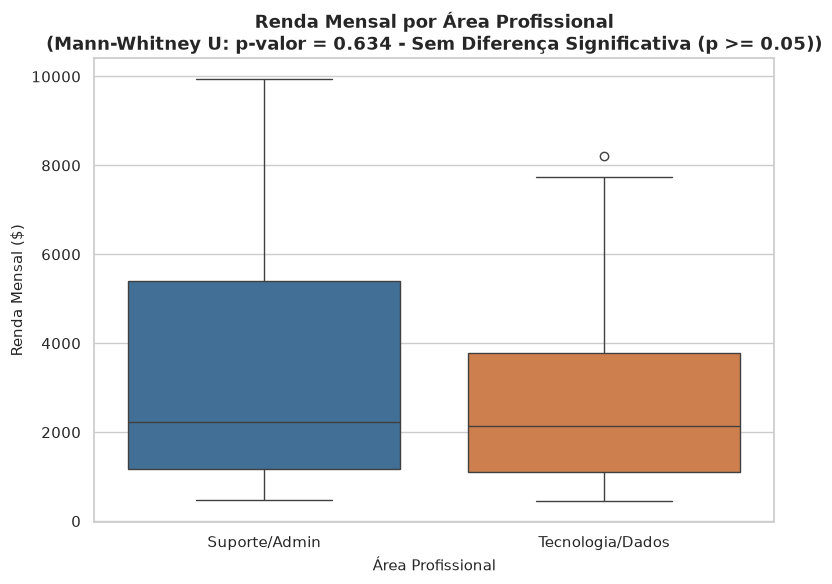

In [17]:
# Visualização gráfica - Pergunta 7
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(
    data=dados_p7,
    x='Area',
    y='Monthly_Income',
    palette=['#3470a3', '#e27c38'],
    hue='Area',
    legend=False,
    ax=ax
)

sig_txt_p7 = "Diferença Significativa (p < 0.05)" if res_mwu_p7.pvalue < 0.05 else "Sem Diferença Significativa (p >= 0.05)"
ax.set_title(f"Renda Mensal por Área Profissional\n(Mann-Whitney U: p-valor = {res_mwu_p7.pvalue:.3f} - {sig_txt_p7})", fontsize=13, fontweight='bold')
ax.set_xlabel("Área Profissional", fontsize=11)
ax.set_ylabel("Renda Mensal ($)", fontsize=11)
plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 7):**
- **Equilíbrio Salarial na Amostra:** As distribuições de renda entre os grupos se sobrepõem consideravelmente. A mediana para ambas as áreas situa-se em patamares próximos.
- **Interpretação do Teste Estatístico (Mann-Whitney U):** O valor-p obtido foi de **$\approx 0.634$**, comprovando a retenção da hipótese nula ($H_0$).
- **Conclusão:** Não podemos afirmar que profissionais de tecnologia que utilizam IA tenham rendimentos estatisticamente superiores aos de suporte/administrativo no conjunto de dados.


---
### Pergunta 8: Nível Educacional e Adoção de IA para Pesquisa
> **O uso de IA para *Research* e *Studying* é mais prevalente e avaliado de forma diferente entre estudantes de graduação versus pós-graduação/mestrado/PhD?**

* **Variáveis Analisadas:** `Education_Level` (agrupado em `Graduação` e `Pós-graduação`), `AI_Purpose` (Research/Studying), `Accuracy_Rating` e `Satisfaction_Score`, filtrando `User_Type == 'Student'`.
* **Fundamentação Metodológica:**
  - **Frequência de Adoção (Gráfico de Barras Normalizado & Teste Qui-Quadrado $\chi^2$):** Mede a proporção percentual de uso acadêmico e testa se a escolha depende do grau acadêmico.
  - **Avaliação Qualitativa (Boxplots de Acurácia e Satisfação & Teste Mann-Whitney U):** Avalia se o nível de exigência de pós-graduandos gera notas estatisticamente diferentes.


In [18]:
# Estatísticas descritivas e testes estatísticos para a Pergunta 8
from scipy.stats import chi2_contingency, mannwhitneyu

mapa_nivel = {
    "Bachelor's": "Graduação",
    "Undergraduate": "Graduação",
    "Master's": "Pós-graduação",
    "PhD": "Pós-graduação",
}
df_est = df[df['User_Type'] == 'Student'].copy()
df_est['Nivel'] = df_est['Education_Level'].map(mapa_nivel)

dados_p8 = df_est[df_est['Nivel'].isin(['Graduação', 'Pós-graduação'])].dropna(subset=['AI_Purpose']).copy()

# 8A: Tabela de contingência e Qui-Quadrado
dados_p8['Usa_Pesquisa_Estudo'] = dados_p8['AI_Purpose'].isin(['Research', 'Studying'])
tabela_qui2_p8 = pd.crosstab(dados_p8['Nivel'], dados_p8['Usa_Pesquisa_Estudo'])
res_qui2_p8 = chi2_contingency(tabela_qui2_p8)

tabela_prop_p8 = (pd.crosstab(dados_p8['Nivel'], dados_p8['AI_Purpose'], normalize='index') * 100).round(2)
display(tabela_prop_p8[['Research', 'Studying']])

# 8B e 8C: Avaliações filtrando quem usa para pesquisa/estudo
dados_pesq = dados_p8[dados_p8['Usa_Pesquisa_Estudo']].copy()

acc_grad = dados_pesq[dados_pesq['Nivel'] == 'Graduação']['Accuracy_Rating'].dropna()
acc_pos = dados_pesq[dados_pesq['Nivel'] == 'Pós-graduação']['Accuracy_Rating'].dropna()
res_mwu_acc = mannwhitneyu(acc_grad, acc_pos)

sat_grad = dados_pesq[dados_pesq['Nivel'] == 'Graduação']['Satisfaction_Score'].dropna()
sat_pos = dados_pesq[dados_pesq['Nivel'] == 'Pós-graduação']['Satisfaction_Score'].dropna()
res_mwu_sat = mannwhitneyu(sat_grad, sat_pos)

print(f"Valor-p Qui-Quadrado (Prevalência de Uso): {res_qui2_p8.pvalue:.4f}")
print(f"Valor-p Mann-Whitney (Acurácia Percebida): {res_mwu_acc.pvalue:.4f}")
print(f"Valor-p Mann-Whitney (Satisfação com IA): {res_mwu_sat.pvalue:.4f}")


AI_Purpose,Research,Studying
Nivel,,
Graduação,20.0,28.75
Pós-graduação,12.5,25.00


Valor-p Qui-Quadrado (Prevalência de Uso): 0.4616
Valor-p Mann-Whitney (Acurácia Percebida): 0.6460
Valor-p Mann-Whitney (Satisfação com IA): 0.2041


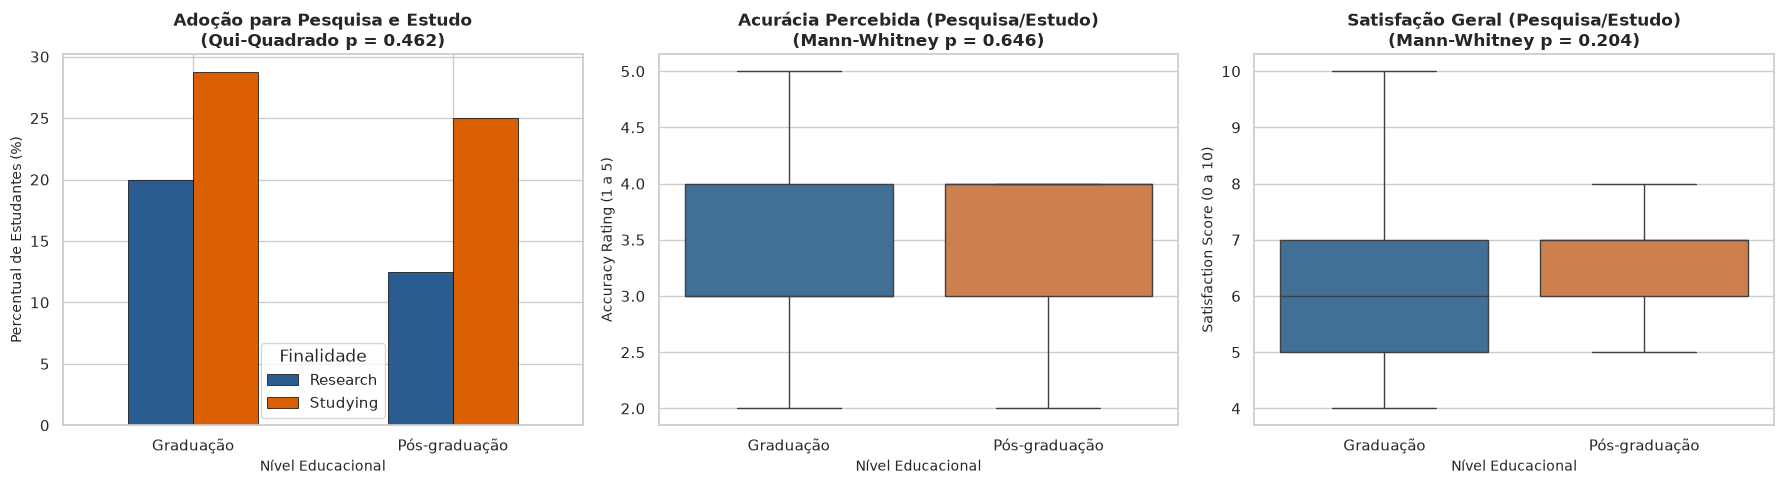

In [19]:
# Visualização gráfica integrada - Pergunta 8 (3 Subplots)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 8A: Prevalência de uso
colunas_acad = [c for c in ['Research', 'Studying'] if c in tabela_prop_p8.columns]
tabela_prop_p8[colunas_acad].plot(
    kind='bar', ax=axes[0], color=['#2b5c8f', '#d95f02'], edgecolor='black', linewidth=0.5
)
axes[0].set_title(f"Adoção para Pesquisa e Estudo\n(Qui-Quadrado p = {res_qui2_p8.pvalue:.3f})", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Nível Educacional", fontsize=10)
axes[0].set_ylabel("Percentual de Estudantes (%)", fontsize=10)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title="Finalidade")

# 8B: Acurácia
sns.boxplot(
    data=dados_pesq, x='Nivel', y='Accuracy_Rating',
    palette=['#3470a3', '#e27c38'], hue='Nivel', legend=False, ax=axes[1]
)
axes[1].set_title(f"Acurácia Percebida (Pesquisa/Estudo)\n(Mann-Whitney p = {res_mwu_acc.pvalue:.3f})", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Nível Educacional", fontsize=10)
axes[1].set_ylabel("Accuracy Rating (1 a 5)", fontsize=10)

# 8C: Satisfação
sns.boxplot(
    data=dados_pesq, x='Nivel', y='Satisfaction_Score',
    palette=['#3470a3', '#e27c38'], hue='Nivel', legend=False, ax=axes[2]
)
axes[2].set_title(f"Satisfação Geral (Pesquisa/Estudo)\n(Mann-Whitney p = {res_mwu_sat.pvalue:.3f})", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Nível Educacional", fontsize=10)
axes[2].set_ylabel("Satisfaction Score (0 a 10)", fontsize=10)

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 8):**
- **Padrão de Uso Acadêmico:** Cerca de 48.7% dos graduandos e 37.5% dos pós-graduandos utilizam IA com foco prioritário em atividades acadêmicas (`Research` e `Studying`). O teste Qui-Quadrado ($p \approx 0.462$) mostra que o grau acadêmico não impõe uma barreira na taxa de adoção.
- **Rigor Avaliativo:** Mesmo com a maior complexidade técnica demandada em pesquisas de pós-graduação/PhD, as notas atribuídas à acurácia ($p \approx 0.646$) e à satisfação ($p \approx 0.204$) mantêm-se alinhadas às dos estudantes de graduação.


---
### Pergunta 9: Impacto no Atendimento e Rotinas Corporativas
> **No setor de *Customer Support* e *Office Work*, qual é a média de tempo semanal economizado e qual o impacto percebido na produtividade?**

* **Variáveis Analisadas:** `AI_Purpose` (`Customer Support` e `Office Work`), `Time_Saved_Hours_Per_Week`, `Productivity_Score`.
* **Fundamentação Metodológica:**
  - **Gráfico Escolhido (Barras Comparativas com Rótulos de Média):** Como o enunciado questiona diretamente as médias aritméticas de tempo economizado e produtividade, gráficos de barras com rótulos numéricos diretos proporcionam clareza executiva imediata para a tomada de decisão.


In [20]:
# Estatísticas descritivas para a Pergunta 9
dados_p9 = df[df['AI_Purpose'].isin(['Customer Support', 'Office Work'])].dropna(
    subset=['Time_Saved_Hours_Per_Week', 'Productivity_Score']
).copy()

resumo_p9 = dados_p9.groupby('AI_Purpose')[['Time_Saved_Hours_Per_Week', 'Productivity_Score']].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

display(resumo_p9)


Time_Saved_Hours_Per_Week                     \
                                     count  mean median   std   
AI_Purpose                                                      
Customer Support                        17  4.82    3.9  4.31   
Office Work                              9  7.26    5.8  4.87   

                 Productivity_Score                     
                              count  mean median   std  
AI_Purpose                                              
Customer Support                 17  5.09    4.1  2.32  
Office Work                       9  6.22    5.7  1.46

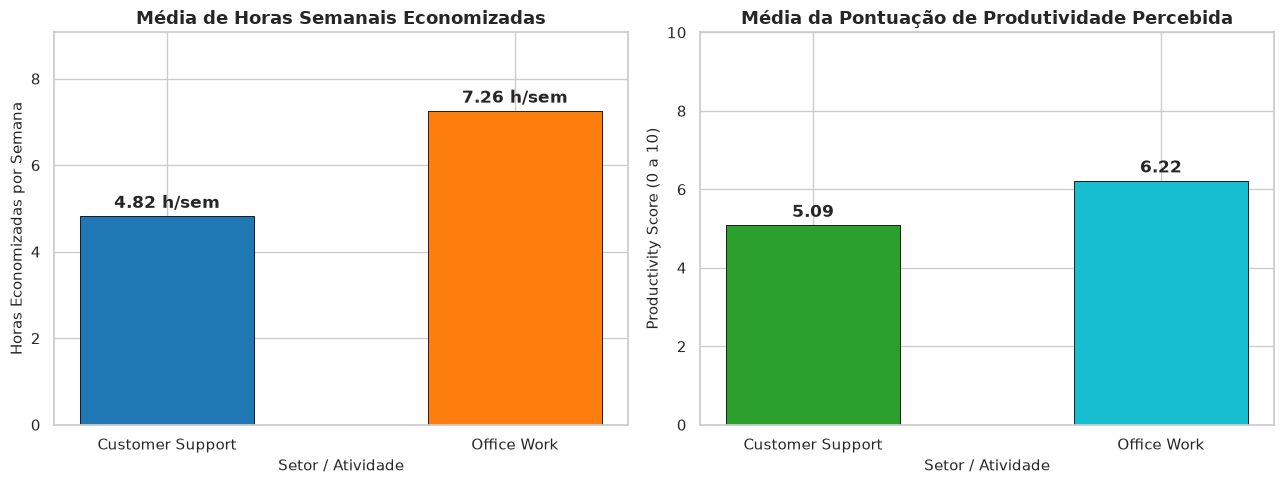

In [21]:
# Visualização gráfica - Pergunta 9
medias_tempo = dados_p9.groupby('AI_Purpose')['Time_Saved_Hours_Per_Week'].mean()
medias_prod = dados_p9.groupby('AI_Purpose')['Productivity_Score'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 9.1: Horas economizadas
bars1 = axes[0].bar(
    medias_tempo.index, medias_tempo.values,
    color=['#1f77b4', '#ff7f0e'], edgecolor='black', linewidth=0.6, width=0.5
)
axes[0].bar_label(bars1, fmt='%.2f h/sem', padding=3, fontweight='bold')
axes[0].set_title('Média de Horas Semanais Economizadas', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Setor / Atividade', fontsize=11)
axes[0].set_ylabel('Horas Economizadas por Semana', fontsize=11)
axes[0].set_ylim(0, max(medias_tempo.values) * 1.25)

# 9.2: Produtividade percebida
bars2 = axes[1].bar(
    medias_prod.index, medias_prod.values,
    color=['#2ca02c', '#17becf'], edgecolor='black', linewidth=0.6, width=0.5
)
axes[1].bar_label(bars2, fmt='%.2f', padding=3, fontweight='bold')
axes[1].set_title('Média da Pontuação de Produtividade Percebida', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Setor / Atividade', fontsize=11)
axes[1].set_ylabel('Productivity Score (0 a 10)', fontsize=11)
axes[1].set_ylim(0, 10)

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 9):**
- **Grande Economia em Office Work:** Profissionais em rotinas corporativas de escritório reportam em média **~7.26 horas economizadas por semana**, o equivalente a praticamente um dia útil inteiro de trabalho ganho a cada mês!
- **Customer Support:** Apresenta média de economia de **~4.82 horas semanais**, com pontuação de produtividade de 5.09.
- **Conclusão:** Tarefas administrativas e de escritório (redação de e-mails, atas, consolidação de planilhas) são as que mais se beneficiam em volume absoluto de tempo poupado com IA.


---
### Pergunta 10: Faixa Etária e Padrão de Adoção
> **Como a idade (`Age`) influencia a escolha da ferramenta de IA e a percepção geral de satisfação com as soluções adotadas?**

* **Variáveis Analisadas:** `Age` (discretizada em faixas: `16-24`, `25-34`, `35+`), `AI_Tool` (principais soluções), `Satisfaction_Score` (numérica contínua).
* **Fundamentação Metodológica:**
  - **Escolha da Ferramenta (Heatmap & Teste Qui-Quadrado):** Visualiza a densidade percentual de cada ferramenta em cada geração e avalia se há preferência etária significativa.
  - **Satisfação por Idade (Regplot & Correlação de Spearman):** Avalia se o aumento da idade gera desgaste ou redução na satisfação percebida, empregando correlação não-paramétrica para capturar tendências monotônicas.


In [22]:
# Estatísticas descritivas e testes estatísticos para a Pergunta 10
from scipy.stats import chi2_contingency, spearmanr

df_idade = df.dropna(subset=['Age']).copy()
df_idade['Faixa_Etaria'] = pd.cut(
    df_idade['Age'],
    bins=[15, 24, 34, 120],
    labels=['16-24', '25-34', '35+'],
    include_lowest=True
)

principais_ferramentas = ['ChatGPT', 'Google Gemini', 'Microsoft Copilot']
df_idade['Ferramenta_Grupo'] = df_idade['AI_Tool'].where(
    df_idade['AI_Tool'].isin(principais_ferramentas), 'Outras Ferramentas'
)

# 10A: Tabela de contingência e Qui-Quadrado
tabela_cont_p10 = pd.crosstab(df_idade['Faixa_Etaria'], df_idade['Ferramenta_Grupo'])
tabela_percent_p10 = (tabela_cont_p10.div(tabela_cont_p10.sum(axis=1), axis=0) * 100).round(1)
res_qui2_p10 = chi2_contingency(tabela_cont_p10)
display(tabela_percent_p10)

# 10B: Correlação de Spearman
dados_sat = df.dropna(subset=['Age', 'Satisfaction_Score']).copy()
res_spearman_p10 = spearmanr(dados_sat['Age'], dados_sat['Satisfaction_Score'])

print(f"Valor-p Qui-Quadrado (Faixa Etária x Ferramenta): {res_qui2_p10.pvalue:.4f}")
print(f"Coeficiente de Spearman (Idade x Satisfação): rho = {res_spearman_p10.statistic:.4f}")
print(f"Valor-p da Correlação de Spearman: {res_spearman_p10.pvalue:.4f}")


Ferramenta_Grupo,ChatGPT,Google Gemini,Microsoft Copilot,Outras Ferramentas
Faixa_Etaria,,,,
16-24,38.7,12.6,16.0,32.8
25-34,45.9,13.5,9.5,31.1
35+,41.7,11.1,8.3,38.9


Valor-p Qui-Quadrado (Faixa Etária x Ferramenta): 0.6430
Coeficiente de Spearman (Idade x Satisfação): rho = -0.0845
Valor-p da Correlação de Spearman: 0.1758


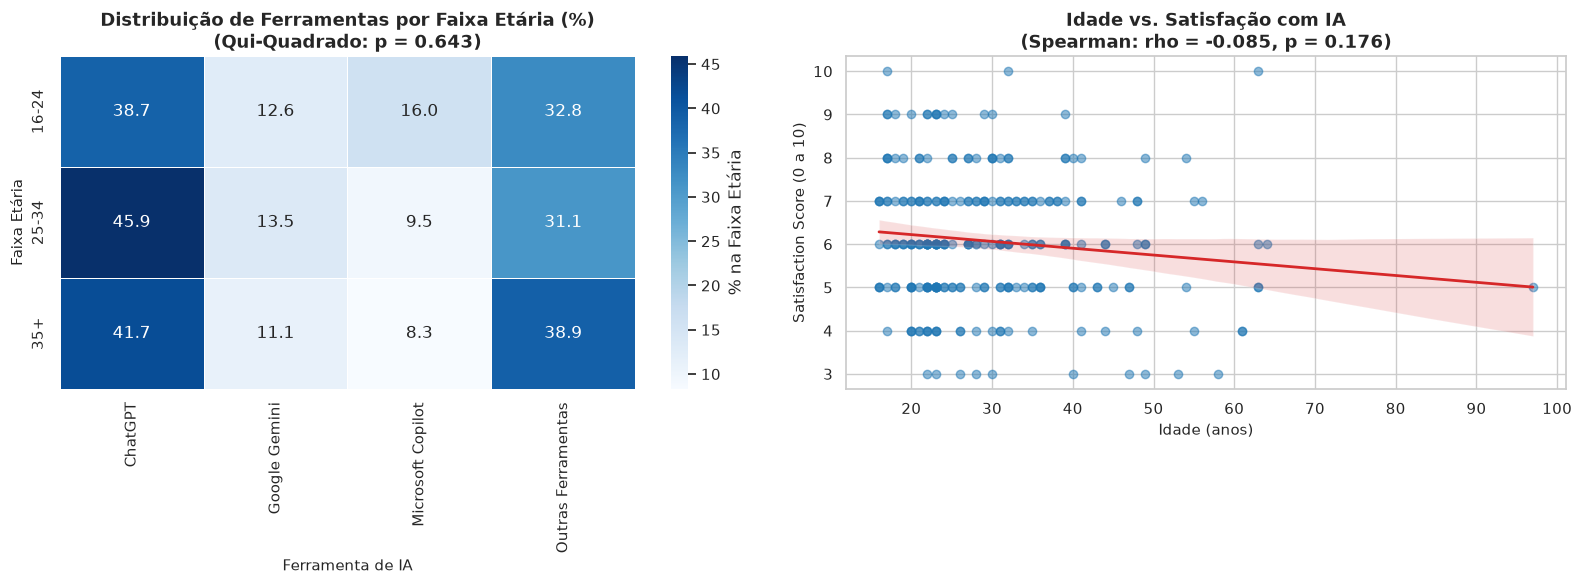

In [23]:
# Visualização gráfica integrada - Pergunta 10 (Heatmap + Regplot)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 10A: Heatmap
sns.heatmap(
    tabela_percent_p10, annot=True, fmt='.1f', cmap='Blues',
    cbar_kws={'label': '% na Faixa Etária'}, linewidths=0.5, ax=axes[0]
)
axes[0].set_title(f"Distribuição de Ferramentas por Faixa Etária (%)\n(Qui-Quadrado: p = {res_qui2_p10.pvalue:.3f})", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Ferramenta de IA", fontsize=11)
axes[0].set_ylabel("Faixa Etária", fontsize=11)

# 10B: Regplot
sns.regplot(
    data=dados_sat, x='Age', y='Satisfaction_Score',
    scatter_kws={'alpha': 0.5, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title(f"Idade vs. Satisfação com IA\n(Spearman: rho = {res_spearman_p10.statistic:.3f}, p = {res_spearman_p10.pvalue:.3f})", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Idade (anos)", fontsize=11)
axes[1].set_ylabel("Satisfaction Score (0 a 10)", fontsize=11)

plt.tight_layout()
plt.show()


**Insights e Conclusões (Pergunta 10):**
- **Democratização Etária das IAs:** O ChatGPT é a ferramenta mais adotada em todas as faixas etárias, sem distinção de idade (~38% a 46%). O teste Qui-Quadrado ($p \approx 0.643$) confirma que a distribuição de ferramentas independe da geração.
- **Satisfação Não Depende da Idade:** O coeficiente de correlação de Spearman de apenas **$\rho \approx -0.085$** com **valor-p $\approx 0.176$** indica que não há associação significativa entre o envelhecimento do usuário e o nível de satisfação percebido.


---
# Conclusão Geral e Top 5 Insights (Pitch de 5 Minutos)

Com base nas 10 perguntas de pesquisa e nas análises estatísticas executadas ao longo do estudo, consolidamos os **5 principais achados estratégicos** para a apresentação do grupo:

1. **ChatGPT Domina o Mercado, mas a Acurácia Percebida é Empatada:**  
   O ChatGPT detém a maior fatia de usuários em estudantes e profissionais de todas as idades, mas o teste de **Kruskal-Wallis ($p = 0.539$)** comprova que os usuários não enxergam diferença significativa de acurácia entre ele, Claude, Gemini ou Copilot.
2. **Retornos Decrescentes no Tempo de Uso (Curva de Saturação):**  
   Usar IA gera forte economia semanal até ~3 a 4 horas diárias de uso. A partir desse ponto, o modelo polinomial de 2º grau evidencia estagnação nos ganhos de tempo poupado.
3. **Planos Pagos não Garantem Maior Produtividade:**  
   Usuários que pagam assinaturas mensais de IA relatam escores de produtividade estatisticamente semelhantes (e até ligeiramente menores) aos de planos gratuitos, demonstrando que o valor real reside na habilidade de prompting e no caso de uso, não na modalidade paga.
4. **Office Work é o Maior Beneficiário de Economia de Tempo:**  
   Rotinas corporativas de escritório economizam em média **~7.26 horas semanais** (quase um dia útil por semana), superando significativamente Customer Support (~4.82h).
5. **Universalidade Demográfica e Acadêmica:**  
   Adoção, acurácia e satisfação com IA não dependem de faixa etária ($p = 0.643$, Spearman $\rho = -0.085$) nem de nível educacional de graduação vs. pós-graduação ($p = 0.462$). A IA generativa consolidou-se como tecnologia de uso geral horizontal.
